# 03 · Noise analysis and the real-hardware run

**What runs on the quantum computer:** the ear-to-ear line of cubes through the centre of our 3D head
(scalp · skull · brain · brain/bleed · brain · skull · scalp) as a 15-qubit unary circuit. A kick at the left scalp;
we measure how much energy has passed **through the skull** into the first brain cube.

We compare four things on the *same* circuit (this is the rubric's 'noise analysis'):
1. exact classical answer  2. noiseless quantum simulator  3. simulated IBM chip noise (FakeKingston, free)
4. real IBM hardware (optional; uses Open Plan minutes; off by default)

Error-handling tricks tested:
* **post-selection**: the physics guarantees exactly one excitation; shots that show 0 or 2+ are known-bad and dropped.
* **zero-noise extrapolation (ZNE)**: run the circuit with deliberately tripled noise (U U† U) and extrapolate back to zero.
* **dynamical decoupling + twirling**: IBM's built-in suppression (hardware only).

⏱ The noisy simulations take ~5–10 min on a laptop (more shots/circuits → use the cluster).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # so `import qwave` works from notebooks/
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RESULTS = pathlib.Path.cwd().parent / "results"; RESULTS.mkdir(exist_ok=True)
from qwave.hardware import ray_problem, build_circuits, run, analyse_counts
from qwave.classical import exact_receiver_energy
from qwave.resources import ibm_qpu_seconds
T, RX = 1.5, 2                      # time; receiver = first brain cube past the skull (qubit 2)
g, c, lab = ray_problem(); gb, cb, labb = ray_problem(bleed=True)
print("healthy ray:", lab, (c * 1500).round()); print("bleed ray:  ", labb, (cb * 1500).round())
exact = {False: exact_receiver_energy(g, c, [T], 0, [RX])[0, 0], True: exact_receiver_energy(gb, cb, [T], 0, [RX])[0, 0]}
print("exact energy through the skull — healthy %.4f, bleed %.4f" % (exact[False], exact[True]))

healthy ray: [1 2 3 3 3 2 1] [1600. 2800. 1546. 1546. 1546. 2800. 1600.]
bleed ray:   [1 2 3 4 3 2 1] [1600. 2800. 1546. 1578. 1546. 2800. 1600.]
exact energy through the skull — healthy 0.1040, bleed 0.1041


## Build the circuits: depth sweep (2,4,6,8 Trotter steps) and a noise-tripled copy for ZNE

In [2]:
circs, meta = build_circuits(t=T, steps_list=(2, 4, 6, 8), folds=(1, 3))
keep = [i for i, m in enumerate(meta) if (not m["bleed"] and (m["fold"] == 1 or m["steps"] == 8)) or (m["bleed"] and m["steps"] == 8 and m["fold"] == 1)]
circs = [circs[i] for i in keep]; meta = [meta[i] for i in keep]
for m in meta: print(m)

{'bleed': False, 'steps': 2, 'fold': 1}
{'bleed': False, 'steps': 4, 'fold': 1}
{'bleed': False, 'steps': 6, 'fold': 1}
{'bleed': False, 'steps': 8, 'fold': 1}
{'bleed': False, 'steps': 8, 'fold': 3}
{'bleed': True, 'steps': 8, 'fold': 1}


In [3]:
SHOTS = 4000
ideal_counts, _ = run(circs, mode="ideal", shots=SHOTS)
noisy_counts, isa = run(circs, mode="fake", shots=SHOTS)      # FakeKingston noise model, ~5-10 min
res = []
for m, ci, cn, ic in zip(meta, ideal_counts, noisy_counts, isa):
    a_i = analyse_counts(ci, RX, 15); a_n = analyse_counts(cn, RX, 15)
    res.append({**m, "cz": ic.count_ops().get("cz", 0), "depth": ic.depth(), "ideal": a_i["raw"],
                "noisy_raw": a_n["raw"], "raw_se": a_n["raw_se"], "noisy_post": a_n["postselected"],
                "post_se": a_n["post_se"], "kept": a_n["kept_fraction"],
                "exact": exact[m["bleed"]]})
import json; json.dump(res, open(RESULTS / "03_noise_results.json", "w"), indent=1, default=float)
for r in res: print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

{'bleed': False, 'steps': 2, 'fold': 1, 'cz': 70, 'depth': 45, 'ideal': 0.0633, 'noisy_raw': 0.0382, 'raw_se': 0.003, 'noisy_post': 0.0548, 'post_se': 0.0043, 'kept': 0.6975, 'exact': np.float64(0.104)}
{'bleed': False, 'steps': 4, 'fold': 1, 'cz': 126, 'depth': 75, 'ideal': 0.0922, 'noisy_raw': 0.0478, 'raw_se': 0.0034, 'noisy_post': 0.0823, 'post_se': 0.0057, 'kept': 0.5803, 'exact': np.float64(0.104)}
{'bleed': False, 'steps': 6, 'fold': 1, 'cz': 182, 'depth': 104, 'ideal': 0.1072, 'noisy_raw': 0.0473, 'raw_se': 0.0034, 'noisy_post': 0.0923, 'post_se': 0.0064, 'kept': 0.5118, 'exact': np.float64(0.104)}
{'bleed': False, 'steps': 8, 'fold': 1, 'cz': 238, 'depth': 130, 'ideal': 0.1013, 'noisy_raw': 0.0467, 'raw_se': 0.0033, 'noisy_post': 0.0958, 'post_se': 0.0067, 'kept': 0.488, 'exact': np.float64(0.104)}
{'bleed': False, 'steps': 8, 'fold': 3, 'cz': 714, 'depth': 388, 'ideal': 0.1008, 'noisy_raw': 0.017, 'raw_se': 0.002, 'noisy_post': 0.0817, 'post_se': 0.0095, 'kept': 0.208, 'exact

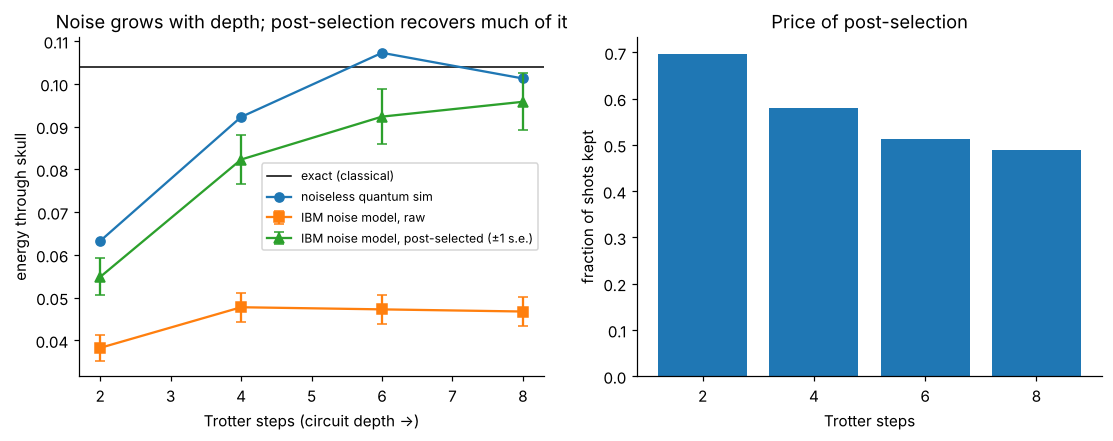

In [4]:
sweep = [r for r in res if not r["bleed"] and r["fold"] == 1]
s = [r["steps"] for r in sweep]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].axhline(exact[False], color="k", lw=1, label="exact (classical)")
ax[0].plot(s, [r["ideal"] for r in sweep], "o-", label="noiseless quantum sim")
ax[0].errorbar(s, [r["noisy_raw"] for r in sweep], yerr=[r["raw_se"] for r in sweep], fmt="s-", capsize=3, label="IBM noise model, raw")
ax[0].errorbar(s, [r["noisy_post"] for r in sweep], yerr=[r["post_se"] for r in sweep], fmt="^-", capsize=3, label="IBM noise model, post-selected (±1 s.e.)")
ax[0].set(xlabel="Trotter steps (circuit depth →)", ylabel="energy through skull", title="Noise grows with depth; post-selection recovers much of it")
ax[0].legend(fontsize=8)
ax[1].bar([str(r["steps"]) for r in sweep], [r["kept"] for r in sweep]); ax[1].set(xlabel="Trotter steps", ylabel="fraction of shots kept", title="Price of post-selection")
plt.savefig(RESULTS / "03_noise.png", bbox_inches="tight"); plt.show()

## Zero-noise extrapolation at 8 steps

In [5]:
r1 = next(r for r in res if not r["bleed"] and r["steps"] == 8 and r["fold"] == 1)
r3 = next(r for r in res if not r["bleed"] and r["steps"] == 8 and r["fold"] == 3)
print(f"CZ gates: scale 1 -> {r1['cz']}, scale 3 -> {r3['cz']} (folding must triple the gates)")
for key, se in (("noisy_raw", "raw_se"), ("noisy_post", "post_se")):
    zne = r1[key] + (r1[key] - r3[key]) / 2          # linear extrapolation from noise scale 1 and 3 to 0
    zse = np.hypot(1.5 * r1[se], 0.5 * r3[se])
    print(f"{key:>11}: scale1={r1[key]:.4f} scale3={r3[key]:.4f} -> ZNE={zne:.4f} ± {zse:.4f}   exact={exact[False]:.4f}")
rb = next(r for r in res if r["bleed"])
print("\nBleed vs healthy at 8 steps (post-selected): %.4f ± %.4f vs %.4f ± %.4f"
      % (rb["noisy_post"], rb["post_se"], r1["noisy_post"], r1["post_se"]))
print("Exact difference: %.4f -> any measured gap here is shot noise / hardware noise, not the bleed" % (exact[True] - exact[False]))

CZ gates: scale 1 -> 238, scale 3 -> 714 (folding must triple the gates)
  noisy_raw: scale1=0.0467 scale3=0.0170 -> ZNE=0.0616 ± 0.0051   exact=0.1040
 noisy_post: scale1=0.0958 scale3=0.0817 -> ZNE=0.1028 ± 0.0111   exact=0.1040

Bleed vs healthy at 8 steps (post-selected): 0.0905 ± 0.0065 vs 0.0958 ± 0.0067
Exact difference: 0.0000 -> any measured gap here is shot noise / hardware noise, not the bleed


## Real IBM hardware (optional — costs Open Plan minutes)

Budget: IBM's rule of thumb is ~2 s per job + ~0.35 ms per shot. Set `RUN_ON_IBM = True` only when the team is ready.
Your API key is typed in at run time and **never saved** (handbook rule). Iterate on the simulator; submit to hardware once.

In [6]:
hw_shots = 4000
print(f"Planned: {len(circs)} circuits x {hw_shots} shots ≈ {ibm_qpu_seconds(len(circs) * hw_shots):.0f} s of QPU time (of 600 s free)")
RUN_ON_IBM = False
if RUN_ON_IBM:
    hw_counts, hw_isa = run(circs, mode="ibm", shots=hw_shots, dd=True, twirl=True)
    hw = [{**m, **analyse_counts(cn, RX, 15)} for m, cn in zip(meta, hw_counts)]
    json.dump(hw, open(RESULTS / "03_hardware_results.json", "w"), indent=1, default=float)
    for r in hw: print(r)

Planned: 6 circuits x 4000 shots ≈ 10 s of QPU time (of 600 s free)


**Takeaways (simulated IBM Kingston noise, 4,000 shots; replace with your hardware numbers after the real run)**

| 8 Trotter steps, 238 CZ, exact = 0.104 | energy through skull |
|---|---|
| noiseless circuit | 0.101 |
| IBM noise, raw | 0.047 ± 0.003: noise halves the signal |
| + post-selection (free, from the physics) | 0.096 ± 0.007, keeping 49% of shots |
| + post-selection + ZNE (scales 1 and 3) | **0.103 ± 0.011**: matches the exact answer within error |
| ZNE on raw counts only | 0.062 ± 0.005: linear extrapolation alone can't undo this much noise |

* Damage grows with circuit depth (shots kept fall from 70% to 49%); post-selection recovers most of it because the physics guarantees exactly one excitation.
* The bleed changes the exact signal by 0.00005, about 100× smaller than the error bar.
  **Bleed detection is not possible on today's hardware at this size.** This is a measured, honest result.